# Experiment 7: Mobile Robot Simulation – Reactive Swarm and Lidar Navigation
**CSAI4014 AISR Laboratory** | Name: Suhani Baderia | SAP ID: 500119327 | Batch: 4

This notebook **simulates both worlds of `github.com/reshamrajs/webots-robotics-sim` in Python**
(NumPy, 2-D kinematics) instead of running them in Webots, then analyses the logs exactly as the
repository's `analysis/metrics.py` does and makes every table and figure for the report.

What is the same as the Webots project: arena and obstacle geometry (from the `.wbt` files), robot start
poses, the 32 ms control step, the 0.32 s logger, the Braitenberg weights and the follow-the-gap steps
(copied from the two controllers), wheel radius / axle / wheel-speed limits, the e-puck IR lookup table and
the 180-beam lidar. What is simpler: no 3-D rigid-body physics (contacts are handled by pushing the round
robot body out of obstacles with a friction factor), and repeats differ through a small random start-pose
jitter and sensor noise (seeded) instead of Webots' non-deterministic physics.

Runs: 11 swarm settings × 3 repeats (120 s) and 5 Pioneer settings × 3 repeats (180 s).
Logs are written to `runs/<world>__<setting>__r<k>.csv` (same columns as the Webots logger: t, robot, x, y, yaw).

In [1]:
import csv
import glob
import math
import os
import platform
import re
import time
from collections import defaultdict
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from matplotlib.transforms import Affine2D

RUNS_DIR = "runs"
WORLDS_DIR = "worlds"
SIMULATOR = "Python 2-D kinematic simulation (NumPy) of the webots-robotics-sim worlds"
SEED = 9327                               # last 4 digits of SAP ID
REPEATS = 3
os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
print("Simulator:", SIMULATOR)
print("Python:", platform.python_version(), "| NumPy:", np.__version__,
      "| Matplotlib:", matplotlib.__version__)
print("OS    :", platform.platform())

Simulator: Python 2-D kinematic simulation (NumPy) of the webots-robotics-sim worlds
Python: 3.10.0 | NumPy: 1.26.4 | Matplotlib: 3.10.5
OS    : Windows-10-10.0.26300-SP0


## 1. Geometry helpers
Ray casting (IR sensors, lidar) against line segments (walls, box edges) and circles (barrels, other robots), and a simple contact model.

In [2]:
# ---------- 2-D geometry: ray casting and collision against walls, boxes and cylinders ----------
def box_segments(cx, cy, sx, sy, a=0.0):
    """4 edge segments [x1, y1, x2, y2] of a rectangle (centre, size, yaw)."""
    c, s = math.cos(a), math.sin(a)
    pts = [(-sx / 2, -sy / 2), (sx / 2, -sy / 2), (sx / 2, sy / 2), (-sx / 2, sy / 2)]
    pts = [(cx + c * x - s * y, cy + s * x + c * y) for x, y in pts]
    return [(*pts[i], *pts[(i + 1) % 4]) for i in range(4)]


def ray_cast(org, dirs, segs, circ, maxr, owner=None):
    """Distance along each ray (org[i] + t*dirs[i]) to the first hit, clipped to maxr.
    segs: (S,4) line segments, circ: (C,3) circles (x, y, r).
    owner[i] = index of the circle that ray i must ignore (its own robot), or -1."""
    d = np.full(len(org), maxr)
    if len(segs):
        p, r = org[:, None, :], dirs[:, None, :]
        q, s = segs[None, :, :2], segs[None, :, 2:] - segs[None, :, :2]
        rxs = r[..., 0] * s[..., 1] - r[..., 1] * s[..., 0]
        qp = q - p
        with np.errstate(divide="ignore", invalid="ignore"):
            t = (qp[..., 0] * s[..., 1] - qp[..., 1] * s[..., 0]) / rxs
            u = (qp[..., 0] * r[..., 1] - qp[..., 1] * r[..., 0]) / rxs
        t = np.where((np.abs(rxs) > 1e-12) & (t >= 0) & (u >= 0) & (u <= 1), t, np.inf)
        d = np.minimum(d, t.min(axis=1))
    if len(circ):
        f = org[:, None, :] - circ[None, :, :2]
        b = (f * dirs[:, None, :]).sum(-1)
        c = (f * f).sum(-1) - circ[None, :, 2] ** 2
        disc = b * b - c
        t = -b - np.sqrt(np.maximum(disc, 0))
        t = np.where(c < 0, 0.0, t)                       # ray starts inside the circle
        t = np.where((disc >= 0) & (t >= 0), t, np.inf)
        if owner is not None:
            t[np.arange(len(org)), owner] = np.where(owner >= 0, np.inf, t[np.arange(len(org)), owner])
        d = np.minimum(d, t.min(axis=1))
    return d


def resolve_collision(pos, rad, segs, circ):
    """Push a round robot body out of every segment/circle it overlaps.
    Returns (new position, True if it was in contact)."""
    hit = False
    for _ in range(3):
        moved = False
        if len(segs):
            a, b = segs[:, :2], segs[:, 2:]
            ab = b - a
            t = np.clip(((pos - a) * ab).sum(1) / (ab * ab).sum(1), 0, 1)
            cp = a + t[:, None] * ab
            dv = pos - cp
            dist = np.hypot(dv[:, 0], dv[:, 1])
            k = np.argmin(dist)
            if dist[k] < rad:
                pos = cp[k] + dv[k] / max(dist[k], 1e-9) * rad
                hit = moved = True
        if len(circ):
            dv = pos - circ[:, :2]
            dist = np.hypot(dv[:, 0], dv[:, 1])
            k = np.argmin(dist - circ[:, 2])
            if dist[k] < rad + circ[k, 2]:
                pos = circ[k, :2] + dv[k] / max(dist[k], 1e-9) * (rad + circ[k, 2])
                hit = moved = True
        if not moved:
            break
    return pos, hit

## 2. The two worlds
Swarm arena 1.6 m × 1.6 m with 3 boxes, 2 barrels and 5 e-pucks; Pioneer room 8 m × 8 m with 5 crates and 4 barrels.

In [3]:
# ---------- The two worlds, with the same geometry as worlds/swarm_arena.wbt and pioneer_lidar.wbt ----------
SWARM_HALF = 0.8                                     # RectangleArena floorSize 1.6 x 1.6 m
SWARM_BOXES = [(0.3, 0.25, 0.10, 0.10, 0.0),          # (x, y, size_x, size_y, yaw)
               (-0.35, -0.2, 0.15, 0.08, 0.6),
               (-0.25, 0.4, 0.08, 0.20, 0.0)]
SWARM_BARRELS = [(0.35, -0.35, 0.04), (0.0, 0.0, 0.05)]  # (x, y, radius)
SWARM_START = {"e-puck1": (0.6, 0.6, 3.9), "e-puck2": (-0.6, 0.6, -0.8), "e-puck3": (-0.6, -0.6, 0.8),
               "e-puck4": (0.6, -0.6, 2.3), "e-puck5": (0.15, 0.6, -1.6)}

ROOM_HALF = 4.0                                      # RectangleArena floorSize 8 x 8 m
ROOM_BOXES = [(1.5, 1.0, 0.6, 0.6, 0.0), (-1.8, 2.2, 1.2, 0.6, 0.0), (-1.2, -1.5, 0.6, 1.0, 0.7),
              (2.4, -2.0, 0.6, 0.6, 0.0), (0.0, 3.0, 2.0, 0.4, 0.0)]
ROOM_BARRELS = [(0.2, -0.4, 0.305), (-2.8, 0.2, 0.305), (3.0, 1.8, 0.305), (1.0, -3.0, 0.305)]
PIONEER_START = (-2.59, -2.43, 2.17)


def static_geometry(half, boxes):
    segs = box_segments(0, 0, 2 * half, 2 * half)          # arena walls (inner faces)
    for b in boxes:
        segs += box_segments(*b)
    return np.array(segs, float)


SWARM_SEGS = static_geometry(SWARM_HALF, SWARM_BOXES)
SWARM_CIRC = np.array(SWARM_BARRELS, float)
ROOM_SEGS = static_geometry(ROOM_HALF, ROOM_BOXES)
ROOM_CIRC = np.array(ROOM_BARRELS, float)

# Obstacles in the format used by draw_obstacles() further down
obs_swarm = [("box", *b) for b in SWARM_BOXES] + [("barrel", *c) for c in SWARM_BARRELS]
obs_pioneer = [("box", *b) for b in ROOM_BOXES] + [("barrel", *c) for c in ROOM_BARRELS]
print(f"swarm arena: {len(SWARM_SEGS)} wall/box edges, {len(SWARM_CIRC)} barrels | "
      f"pioneer room: {len(ROOM_SEGS)} edges, {len(ROOM_CIRC)} barrels")

swarm arena: 16 wall/box edges, 2 barrels | pioneer room: 24 edges, 4 barrels


## 3. e-puck swarm: Braitenberg vehicle
Each step (32 ms): read 8 IR sensors through the lookup table, scale $x_i=\min(ps_i,4096)/4096$, then
$v_L = \text{cruise} + \text{wiring}\cdot\text{gain}\sum_i w^L_i x_i$, $v_R$ likewise; clip to [−1, 1], multiply by
6.28 rad/s × per-robot bias (0.85–0.97) × `speed`. `wiring = −1` swaps the weight signs (Exercise 2).

In [4]:
# ---------- e-puck swarm: Braitenberg controller (same law and weights as epuck_braitenberg.py) ----------
DT = 0.032                      # s, basicTimeStep 32 ms
LOG_EVERY = 10                  # logger samples every 0.32 s
EPUCK_R, EPUCK_WHEEL_R, EPUCK_AXLE = 0.037, 0.0205, 0.052
EPUCK_MAX_W = 6.28              # rad/s wheel limit
W_LEFT = np.array([-1.3, -1.0, -0.5, 0.0, 0.0, 0.5, 1.0, 1.3])
W_RIGHT = np.array([1.3, 1.0, 0.5, 0.0, 0.0, -0.5, -1.0, -1.3])
PS_ANGLE = np.array([-0.30, -0.80, -1.57, -2.64, 2.64, 1.57, 0.80, 0.30])   # ps0..ps7, rad from heading
# e-puck IR lookup table (distance m -> raw value), as in the Webots E-puck PROTO
IR_D = np.array([0.0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07])
IR_V = np.array([4095, 2133.33, 1465.73, 601.46, 383.84, 234.93, 158.03, 120.0, 104.09, 67.19])
IR_RANGE = IR_D[-1]


def simulate_swarm(params=None, seconds=120, seed=0, snapshot_at=None):
    P = {"cruise": 0.5, "gain": 4.0, "speed": 1.0, "noise": 0.0, "wiring": 1.0}
    P.update(params or {})
    rng = np.random.default_rng(seed)
    names = list(SWARM_START)
    n = len(names)
    # small random start-pose jitter: stands in for Webots' non-repeatable physics between repeats
    pose = np.array([SWARM_START[k] for k in names], float)
    pose[:, :2] += rng.normal(0, 0.005, (n, 2))
    pose[:, 2] += rng.normal(0, 0.03, n)
    bias = np.array([0.85 + 0.03 * (sum(map(ord, k)) % 5) for k in names])
    log, snap = [], None
    steps = int(round(seconds / DT))
    for step in range(1, steps + 1):
        # --- sense: 8 IR rays per robot, starting at the body edge ---
        ang = pose[:, 2:3] + PS_ANGLE[None, :]
        dirs = np.stack([np.cos(ang), np.sin(ang)], -1).reshape(-1, 2)
        org = np.repeat(pose[:, :2], 8, 0) + dirs * (EPUCK_R - 0.002)
        robots = np.c_[pose[:, :2], np.full(n, EPUCK_R)]
        circ = np.vstack([SWARM_CIRC, robots])
        owner = len(SWARM_CIRC) + np.repeat(np.arange(n), 8)
        dist = ray_cast(org, dirs, SWARM_SEGS, circ, IR_RANGE, owner).reshape(n, 8)
        raw = np.interp(dist, IR_D, IR_V) * (1 + rng.normal(0, 0.02, dist.shape))
        x = np.clip(raw, 0, 4096) / 4096
        # --- think: Braitenberg law ---
        vl = P["cruise"] + P["wiring"] * (x @ W_LEFT) * P["gain"]
        vr = P["cruise"] + P["wiring"] * (x @ W_RIGHT) * P["gain"]
        if P["noise"] > 0:
            vl = vl + rng.normal(0, P["noise"], n)
            vr = vr + rng.normal(0, P["noise"], n)
        k = EPUCK_MAX_W * bias * P["speed"]
        wl, wr = np.clip(vl, -1, 1) * k, np.clip(vr, -1, 1) * k
        # --- act: differential-drive kinematics, then contacts ---
        v = EPUCK_WHEEL_R * (wl + wr) / 2
        w = EPUCK_WHEEL_R * (wr - wl) / EPUCK_AXLE
        for i in range(n):
            th = pose[i, 2] + w[i] * DT / 2
            new = pose[i, :2] + v[i] * DT * np.array([math.cos(th), math.sin(th)])
            others = np.c_[np.delete(pose[:, :2], i, 0), np.full(n - 1, EPUCK_R)]
            new, hit = resolve_collision(new, EPUCK_R, SWARM_SEGS, np.vstack([SWARM_CIRC, others]))
            if hit:   # wheel friction against the obstacle: only a little sliding along it
                new = pose[i, :2] + 0.3 * (new - pose[i, :2])
                new, _ = resolve_collision(new, EPUCK_R, SWARM_SEGS, np.vstack([SWARM_CIRC, others]))
            pose[i, :2] = new
            pose[i, 2] = (pose[i, 2] + w[i] * DT + math.pi) % (2 * math.pi) - math.pi
        if step % LOG_EVERY == 0:
            t = step * DT
            log += [(t, names[i], *pose[i]) for i in range(n)]
            if snapshot_at is not None and snap is None and t >= snapshot_at:
                snap = {"t": t, "pose": pose.copy(), "dist": dist.copy(), "names": names}
    return log, snap

## 4. Pioneer 3-DX: follow-the-gap with a 180-beam lidar
Clip scan to `lookahead`, mark beams > `free` as free, cut a bubble of half-angle $\arctan(\text{bubble}/r_{min})$ around the
nearest return, steer to the middle of the widest gap; $v=\min(\text{max\_v},\text{slow}\cdot d_{front})$ (0 if $d_{front}<\text{stop}$),
$\omega=\text{clip}(k_{turn}\theta,\pm\text{max\_w})$, then $\omega_{L,R}=(v\mp\omega L/2)/R$ with $R=0.0975$ m, $L=0.33$ m.

In [5]:
# ---------- Pioneer 3-DX with a 180-beam lidar: follow-the-gap (same steps as pioneer_lidar_nav.py) ----------
P3_R, P3_WHEEL_R, P3_AXLE, P3_MAX_W = 0.22, 0.0975, 0.33, 12.3   # body radius m, wheel radius m, axle m, rad/s
LIDAR_N, LIDAR_FOV, LIDAR_X = 180, math.pi, 0.136
LIDAR_ANG = LIDAR_FOV / 2 - np.arange(LIDAR_N) * LIDAR_FOV / (LIDAR_N - 1)   # +90 deg (left) .. -90 deg (right)


def widest_gap(free):
    """(start, end) of the longest run of True values (end exclusive)."""
    f = np.r_[False, free, False].astype(int)
    edges = np.flatnonzero(np.diff(f))
    starts, ends = edges[::2], edges[1::2]
    if len(starts) == 0:
        return 0, 0
    k = np.argmax(ends - starts)
    return starts[k], ends[k]


def simulate_pioneer(params=None, seconds=180, seed=0, scan_at=None):
    P = {"lookahead": 2.5, "free": 1.0, "bubble": 0.45, "stop": 0.35, "max_v": 0.6,
         "slow": 0.35, "k_turn": 2.0, "max_w": 1.5}
    P.update(params or {})
    rng = np.random.default_rng(seed)
    x, y, th = PIONEER_START
    x, y, th = x + rng.normal(0, 0.01), y + rng.normal(0, 0.01), th + rng.normal(0, 0.02)
    wl_act = wr_act = 0.0
    log, scan = [], None
    steps = int(round(seconds / DT))
    for step in range(1, steps + 1):
        # --- sense: lidar scan with 5 mm noise ---
        ang = th + LIDAR_ANG
        dirs = np.c_[np.cos(ang), np.sin(ang)]
        org = np.tile([x + LIDAR_X * math.cos(th), y + LIDAR_X * math.sin(th)], (LIDAR_N, 1))
        r = ray_cast(org, dirs, ROOM_SEGS, ROOM_CIRC, 80.0) + rng.normal(0, 0.005, LIDAR_N)
        r = np.minimum(r, P["lookahead"])
        # --- think: follow the gap ---
        k = int(np.argmin(r))
        dmin = r[k]
        free = r > P["free"]
        if dmin < P["lookahead"]:
            half = math.atan2(P["bubble"], max(dmin, 1e-3))
            free[np.abs(LIDAR_ANG - LIDAR_ANG[k]) < half] = False
        a, b = widest_gap(free)
        target = LIDAR_ANG[(a + b - 1) // 2] if b > a else math.pi / 2
        front = r[LIDAR_N // 3: 2 * LIDAR_N // 3].min()
        v = 0.0 if front < P["stop"] else min(P["max_v"], P["slow"] * front)
        w = float(np.clip(P["k_turn"] * target, -P["max_w"], P["max_w"]))
        wl = (v - w * P3_AXLE / 2) / P3_WHEEL_R
        wr = (v + w * P3_AXLE / 2) / P3_WHEEL_R
        s = max(1.0, abs(wl) / P3_MAX_W, abs(wr) / P3_MAX_W)
        # --- act: motors follow the command with a 0.1 s lag, then kinematics + contacts ---
        alpha = DT / (0.1 + DT)
        wl_act += alpha * (wl / s - wl_act)
        wr_act += alpha * (wr / s - wr_act)
        va = P3_WHEEL_R * (wl_act + wr_act) / 2
        wa = P3_WHEEL_R * (wr_act - wl_act) / P3_AXLE
        thm = th + wa * DT / 2
        new = np.array([x + va * DT * math.cos(thm), y + va * DT * math.sin(thm)])
        new, hit = resolve_collision(new, P3_R, ROOM_SEGS, ROOM_CIRC)
        if hit:
            new = np.array([x, y]) + 0.3 * (new - np.array([x, y]))
            new, _ = resolve_collision(new, P3_R, ROOM_SEGS, ROOM_CIRC)
        x, y = new
        th = (th + wa * DT + math.pi) % (2 * math.pi) - math.pi
        if step % LOG_EVERY == 0:
            log.append((step * DT, "pioneer", x, y, th))
        if scan_at is not None and scan is None and step * DT >= scan_at:
            scan = {"pose": (x, y, th), "r": r.copy(), "free": free.copy(), "target": target}
    return log, scan

## 5. Run every setting (3 repeats each) and write the logs
Same plan as `run_all_exp07.py`: Part A, Part B, Exercise 1 (cruise sweep) and Exercise 2 (swapped wiring).

In [6]:
PLAN = [
    # Part A: e-puck swarm (Table 7.1)
    ("swarm", "default", {}), ("swarm", "cruise-0.9", {"cruise": 0.9}), ("swarm", "gain-1", {"gain": 1}),
    ("swarm", "gain-10", {"gain": 10}), ("swarm", "noise-0.3", {"noise": 0.3}),
    # Exercise 1: speed vs safety, cruise sweep (0.5 = default)
    ("swarm", "cruise-0.2", {"cruise": 0.2}), ("swarm", "cruise-0.4", {"cruise": 0.4}),
    ("swarm", "cruise-0.6", {"cruise": 0.6}), ("swarm", "cruise-0.8", {"cruise": 0.8}),
    ("swarm", "cruise-1.0", {"cruise": 1.0}),
    # Exercise 2: swapped wiring ("aggressive" vehicle)
    ("swarm", "wiring-aggressive", {"wiring": -1}),
    # Part B: Pioneer 3-DX with lidar (Table 7.2)
    ("pioneer", "default", {}), ("pioneer", "bubble-0.15", {"bubble": 0.15}),
    ("pioneer", "bubble-0.9", {"bubble": 0.9}), ("pioneer", "k_turn-0.5", {"k_turn": 0.5}),
    ("pioneer", "stop-0.8", {"stop": 0.8}),
]
os.makedirs(RUNS_DIR, exist_ok=True)
t_start = time.time()
for j, (world, label, prm) in enumerate(PLAN):
    for k in range(1, REPEATS + 1):
        seed = SEED * 1000 + 10 * j + k
        if world == "swarm":
            log, _ = simulate_swarm(prm, seconds=120, seed=seed)
        else:
            log, _ = simulate_pioneer(prm, seconds=180, seed=seed)
        with open(os.path.join(RUNS_DIR, f"{world}__{label}__r{k}.csv"), "w", newline="") as f:
            w = csv.writer(f)
            w.writerow(["t", "robot", "x", "y", "yaw"])
            w.writerows([(f"{t:.3f}", n, f"{x:.4f}", f"{y:.4f}", f"{a:.4f}") for t, n, x, y, a in log])
    print(f"{world:8s} {label:20s} {REPEATS} repeats done   ({time.time() - t_start:5.1f} s elapsed)")

swarm    default              3 repeats done   (  5.9 s elapsed)


swarm    cruise-0.9           3 repeats done   ( 13.7 s elapsed)


swarm    gain-1               3 repeats done   ( 20.1 s elapsed)


swarm    gain-10              3 repeats done   ( 27.0 s elapsed)


swarm    noise-0.3            3 repeats done   ( 31.8 s elapsed)


swarm    cruise-0.2           3 repeats done   ( 36.2 s elapsed)


... (6 outputs left out)

pioneer  bubble-0.15          3 repeats done   ( 78.9 s elapsed)


pioneer  bubble-0.9           3 repeats done   ( 86.2 s elapsed)


pioneer  k_turn-0.5           3 repeats done   ( 92.6 s elapsed)


pioneer  stop-0.8             3 repeats done   ( 98.7 s elapsed)


## Load the runs and compute metrics
Metrics are the same as `analysis/metrics.py` of the repository:
path length (m), mean speed (m/s), stuck % (share of samples moving < 1 cm/s) and coverage
(share of grid cells visited; 10 cm cells in the 1.6 m swarm arena, 50 cm cells in the 8 m room).

In [7]:
GRID = {"swarm": (0.8, 0.1), "pioneer": (4.0, 0.5)}      # (half-width m, cell m)

def load_tracks(path):
    tracks = defaultdict(list)
    with open(path) as f:
        for r in csv.DictReader(f):
            tracks[r["robot"]].append((float(r["t"]), float(r["x"]), float(r["y"])))
    return {k: np.array(v) for k, v in tracks.items()}

def metrics(tracks, world):
    half, cell = GRID[world]
    n = int(round(2 * half / cell))
    visited, per_robot = set(), {}
    for name, p in sorted(tracks.items()):
        d = np.hypot(np.diff(p[:, 1]), np.diff(p[:, 2]))
        dt = np.maximum(np.diff(p[:, 0]), 1e-9)
        length = d.sum()
        stuck = 100 * np.mean(d / dt < 0.01)
        dur = p[-1, 0] - p[0, 0]
        per_robot[name] = (length, length / max(dur, 1e-9), stuck)
        for x, y in p[:, 1:3]:
            visited.add((min(n - 1, int((x + half) / cell)), min(n - 1, int((y + half) / cell))))
    return per_robot, 100 * len(visited) / n**2

runs = defaultdict(list)          # (world, setting) -> list of dicts
for f in sorted(glob.glob(os.path.join(RUNS_DIR, "*__*__r*.csv"))):
    m = re.match(r"(swarm|pioneer)__(.+)__r(\d+)\.csv$", os.path.basename(f))
    if not m:
        continue
    world, setting, rep = m.group(1), m.group(2), int(m.group(3))
    tr = load_tracks(f)
    per, cov = metrics(tr, world)
    runs[(world, setting)].append({"rep": rep, "file": f, "tracks": tr, "per": per, "cov": cov,
                                   "dur": max(p[-1, 0] for p in tr.values())})
if not runs:
    raise SystemExit(f"No run files found in '{RUNS_DIR}/'. Follow the steps at the top first.")
for (w, s), lst in sorted(runs.items()):
    print(f"{w:8s} {s:20s} repeats: {len(lst)}  duration ≈ {lst[0]['dur']:.0f} s")

def ms(values, fmt="{:.1f}"):
    v = np.asarray(values, float)
    return (fmt + " ± " + fmt).format(v.mean(), v.std(ddof=1) if len(v) > 1 else 0.0)

pioneer  bubble-0.15          repeats: 3  duration ≈ 180 s
pioneer  bubble-0.9           repeats: 3  duration ≈ 180 s
pioneer  default              repeats: 3  duration ≈ 180 s
pioneer  k_turn-0.5           repeats: 3  duration ≈ 180 s
pioneer  stop-0.8             repeats: 3  duration ≈ 180 s
swarm    cruise-0.2           repeats: 3  duration ≈ 120 s
swarm    cruise-0.4           repeats: 3  duration ≈ 120 s
swarm    cruise-0.6           repeats: 3  duration ≈ 120 s
swarm    cruise-0.8           repeats: 3  duration ≈ 120 s
swarm    cruise-0.9           repeats: 3  duration ≈ 120 s
swarm    cruise-1.0           repeats: 3  duration ≈ 120 s
swarm    default              repeats: 3  duration ≈ 120 s
swarm    gain-1               repeats: 3  duration ≈ 120 s
swarm    gain-10              repeats: 3  duration ≈ 120 s
swarm    noise-0.3            repeats: 3  duration ≈ 120 s
swarm    wiring-aggressive    repeats: 3  duration ≈ 120 s


## Table 7.1 – Part A, e-puck swarm (120 s runs, mean ± std over repeats)

In [8]:
order_a = ["default", "cruise-0.2", "cruise-0.9", "gain-1", "gain-10", "noise-0.3"]
rows_a = []
hdr_a = ["Setting", "Repeats", "Mean path per robot (m)", "Mean speed (m/s)", "Worst robot stuck (%)",
         "Coverage (%)", "Coverage per repeat (%)"]
print(f"{hdr_a[0]:<14}{hdr_a[1]:>8}{hdr_a[2]:>25}{hdr_a[3]:>20}{hdr_a[4]:>24}{hdr_a[5]:>16}   {hdr_a[6]}")
for s in order_a:
    lst = runs.get(("swarm", s))
    if not lst:
        continue
    path = [np.mean([v[0] for v in r["per"].values()]) for r in lst]
    speed = [np.mean([v[1] for v in r["per"].values()]) for r in lst]
    worst = [max(v[2] for v in r["per"].values()) for r in lst]
    cov = [r["cov"] for r in lst]
    row = [s, len(lst), ms(path, "{:.2f}"), ms(speed, "{:.3f}"), ms(worst), ms(cov),
           " / ".join(f"{c:.0f}" for c in cov)]
    rows_a.append(row)
    print(f"{row[0]:<14}{row[1]:>8}{row[2]:>25}{row[3]:>20}{row[4]:>24}{row[5]:>16}   {row[6]}")
np.savetxt("tables/T7_1_partA_swarm.csv", np.array(rows_a, dtype=object), fmt="%s", delimiter=";",
           header=";".join(hdr_a), comments="")

Setting        Repeats  Mean path per robot (m)    Mean speed (m/s)   Worst robot stuck (%)    Coverage (%)   Coverage per repeat (%)
default              3              6.99 ± 0.00       0.058 ± 0.000               0.0 ± 0.0      82.2 ± 0.8   83 / 81 / 82
cruise-0.2           3              2.80 ± 0.00       0.023 ± 0.000               0.0 ± 0.0      56.2 ± 0.4   56 / 57 / 56
cruise-0.9           3             11.37 ± 1.39       0.095 ± 0.012             11.3 ± 19.4      91.7 ± 2.2   91 / 90 / 94
gain-1               3              6.73 ± 0.40       0.056 ± 0.003             17.2 ± 29.6      79.9 ± 7.8   71 / 86 / 83
gain-10              3              6.72 ± 0.49       0.056 ± 0.004             18.7 ± 32.4      80.5 ± 3.1   83 / 77 / 82
noise-0.3            3              6.89 ± 0.02       0.058 ± 0.000               0.0 ± 0.0      82.8 ± 2.1   84 / 84 / 80


## Table 7.2 – Part B, Pioneer 3-DX with lidar (180 s runs)

In [9]:
order_b = ["default", "bubble-0.15", "bubble-0.9", "k_turn-0.5", "stop-0.8"]
rows_b = []
hdr_b = ["Setting", "Repeats", "Distance (m)", "Mean speed (m/s)", "Stuck (%)", "Coverage (%)"]
print(f"{hdr_b[0]:<14}{hdr_b[1]:>8}{hdr_b[2]:>18}{hdr_b[3]:>20}{hdr_b[4]:>16}{hdr_b[5]:>16}")
for s in order_b:
    lst = runs.get(("pioneer", s))
    if not lst:
        continue
    v = [r["per"]["pioneer"] if "pioneer" in r["per"] else list(r["per"].values())[0] for r in lst]
    row = [s, len(lst), ms([x[0] for x in v]), ms([x[1] for x in v], "{:.3f}"),
           ms([x[2] for x in v]), ms([r["cov"] for r in lst])]
    rows_b.append(row)
    print(f"{row[0]:<14}{row[1]:>8}{row[2]:>18}{row[3]:>20}{row[4]:>16}{row[5]:>16}")
np.savetxt("tables/T7_2_partB_pioneer.csv", np.array(rows_b, dtype=object), fmt="%s", delimiter=";",
           header=";".join(hdr_b), comments="")

Setting        Repeats      Distance (m)    Mean speed (m/s)       Stuck (%)    Coverage (%)
default              3        82.5 ± 0.7       0.460 ± 0.004       0.0 ± 0.0      22.0 ± 0.9
bubble-0.15          3        74.4 ± 0.0       0.414 ± 0.000       0.0 ± 0.0      27.2 ± 1.1
bubble-0.9           3        82.5 ± 0.4       0.459 ± 0.002       0.0 ± 0.0      23.4 ± 0.4
k_turn-0.5           3        74.1 ± 0.0       0.413 ± 0.000       0.0 ± 0.0      29.2 ± 1.0
stop-0.8             3        10.4 ± 1.1       0.058 ± 0.006      86.0 ± 2.4       9.5 ± 1.1


## Drawing helper

In [10]:
def draw_obstacles(ax, obs):
    for o in obs:
        if o[0] == "box":
            _, x, y, sx, sy, a = o
            r = Rectangle((-sx / 2, -sy / 2), sx, sy, color="saddlebrown", alpha=0.7, zorder=1)
            r.set_transform(Affine2D().rotate(a).translate(x, y) + ax.transData)
            ax.add_patch(r)
        else:
            ax.add_patch(Circle((o[1], o[2]), o[3], color="dimgray", alpha=0.8, zorder=1))

## Figure 7.1 – snapshot of the running swarm simulation and a Pioneer lidar scan
(Top-down view rendered from the simulation state; it replaces the Webots window screenshot.)

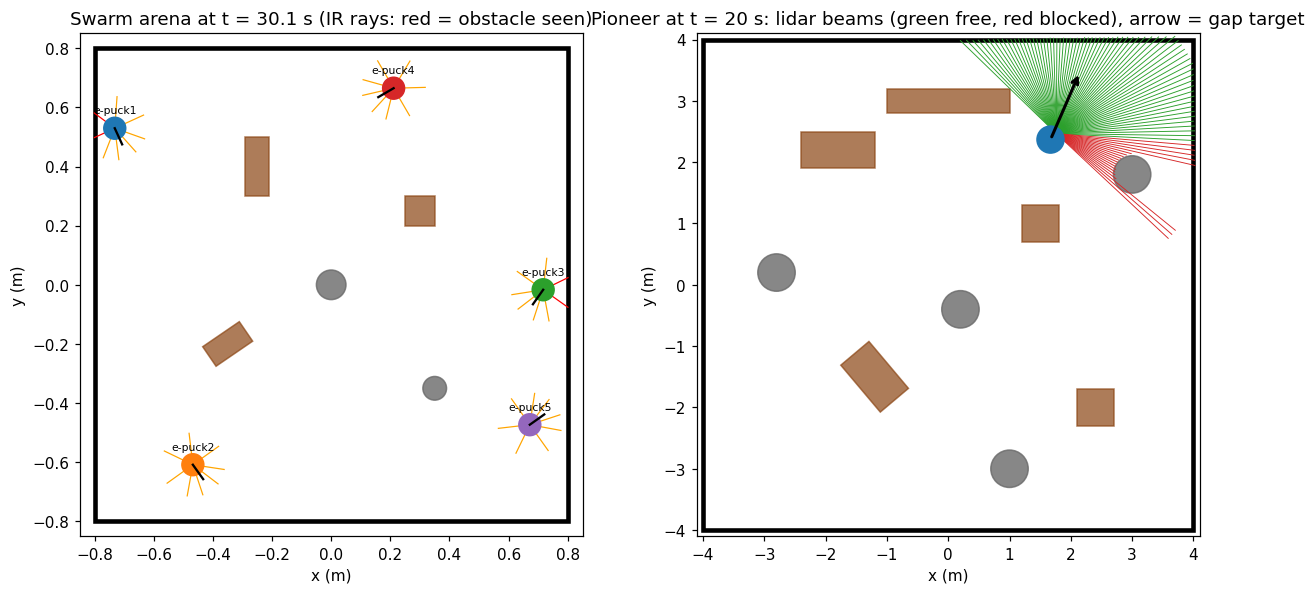

In [11]:
_, snap = simulate_swarm({}, seconds=31, seed=SEED, snapshot_at=30)
_, scan = simulate_pioneer({}, seconds=20, seed=SEED, scan_at=20)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5.4))
a1.add_patch(Rectangle((-SWARM_HALF, -SWARM_HALF), 2 * SWARM_HALF, 2 * SWARM_HALF, fill=False, lw=3, color="k"))
draw_obstacles(a1, obs_swarm)
for i, name in enumerate(snap["names"]):
    x, y, th = snap["pose"][i]
    a1.add_patch(Circle((x, y), EPUCK_R, color=f"C{i}", zorder=3))
    a1.plot([x, x + 0.06 * math.cos(th)], [y, y + 0.06 * math.sin(th)], "k-", lw=1.5, zorder=4)
    for s in range(8):
        a = th + PS_ANGLE[s]
        d = snap["dist"][i, s]
        x0, y0 = x + EPUCK_R * math.cos(a), y + EPUCK_R * math.sin(a)
        a1.plot([x0, x0 + d * math.cos(a)], [y0, y0 + d * math.sin(a)],
                color="r" if d < IR_RANGE else "orange", lw=0.8, zorder=2)
    a1.annotate(name, (x, y + 0.05), ha="center", fontsize=7)
a1.set(xlim=(-0.85, 0.85), ylim=(-0.85, 0.85), aspect="equal", xlabel="x (m)", ylabel="y (m)",
       title=f"Swarm arena at t = {snap['t']:.1f} s
IR rays: red = obstacle seen, orange = clear")
x, y, th = scan["pose"]
a2.add_patch(Rectangle((-ROOM_HALF, -ROOM_HALF), 2 * ROOM_HALF, 2 * ROOM_HALF, fill=False, lw=3, color="k"))
draw_obstacles(a2, obs_pioneer)
lx, ly = x + LIDAR_X * math.cos(th), y + LIDAR_X * math.sin(th)
for i in range(0, LIDAR_N, 2):
    a = th + LIDAR_ANG[i]
    a2.plot([lx, lx + scan["r"][i] * math.cos(a)], [ly, ly + scan["r"][i] * math.sin(a)],
            color="tab:green" if scan["free"][i] else "tab:red", lw=0.6, zorder=2)
a2.add_patch(Circle((x, y), P3_R, color="tab:blue", zorder=3))
a2.annotate("", (x + 1.2 * math.cos(th + scan["target"]), y + 1.2 * math.sin(th + scan["target"])), (x, y),
            arrowprops=dict(arrowstyle="->", lw=2, color="k"), zorder=4)
a2.set(xlim=(-4.1, 4.1), ylim=(-4.1, 4.1), aspect="equal", xlabel="x (m)", ylabel="y (m)",
       title="Pioneer at t = 20 s
lidar beams: green free, red blocked; arrow = gap target")
fig.tight_layout()
fig.savefig("figs/fig7_1_simulation_snapshot.png")
plt.show()

## Figure 7.2 – swarm trajectories and coverage (default setting, repeat 1)

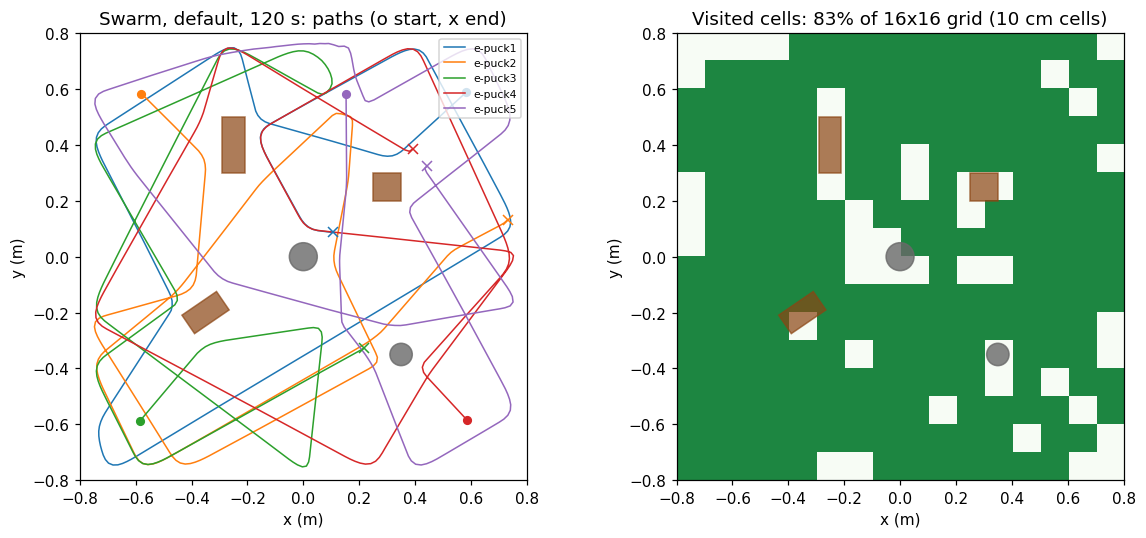

In [12]:
def plot_run(run, world, obs, title, fname):
    half, cell = GRID[world]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5))
    allp = []
    for name, p in sorted(run["tracks"].items()):
        a1.plot(p[:, 1], p[:, 2], lw=1, label=name, zorder=2)
        a1.plot(p[0, 1], p[0, 2], "o", ms=5, color=a1.lines[-1].get_color(), zorder=3)
        a1.plot(p[-1, 1], p[-1, 2], "x", ms=7, color=a1.lines[-1].get_color(), zorder=3)
        allp.append(p[:, 1:3])
    draw_obstacles(a1, obs)
    a1.set(xlim=(-half, half), ylim=(-half, half), aspect="equal", xlabel="x (m)", ylabel="y (m)",
           title=f"{title}: paths (o start, x end)")
    a1.legend(fontsize=7, loc="upper right")
    allp = np.vstack(allp)
    n = int(round(2 * half / cell))
    H, _, _ = np.histogram2d(allp[:, 0], allp[:, 1], bins=n, range=[[-half, half], [-half, half]])
    a2.imshow(H.T > 0, origin="lower", extent=(-half, half, -half, half), cmap="Greens", vmin=0, vmax=1.3)
    draw_obstacles(a2, obs)
    a2.set(aspect="equal", xlabel="x (m)", ylabel="y (m)",
           title=f"Visited cells: {run['cov']:.0f}% of {n}x{n} grid ({cell*100:.0f} cm cells)")
    fig.tight_layout()
    fig.savefig(fname)
    plt.show()

if ("swarm", "default") in runs:
    plot_run(runs[("swarm", "default")][0], "swarm", obs_swarm, "Swarm, default, 120 s",
             "figs/fig7_2_swarm_trajectories_coverage.png")

## Figure 7.3 – Pioneer trajectory in the 8 m × 8 m room (default and bubble = 0.15 m)

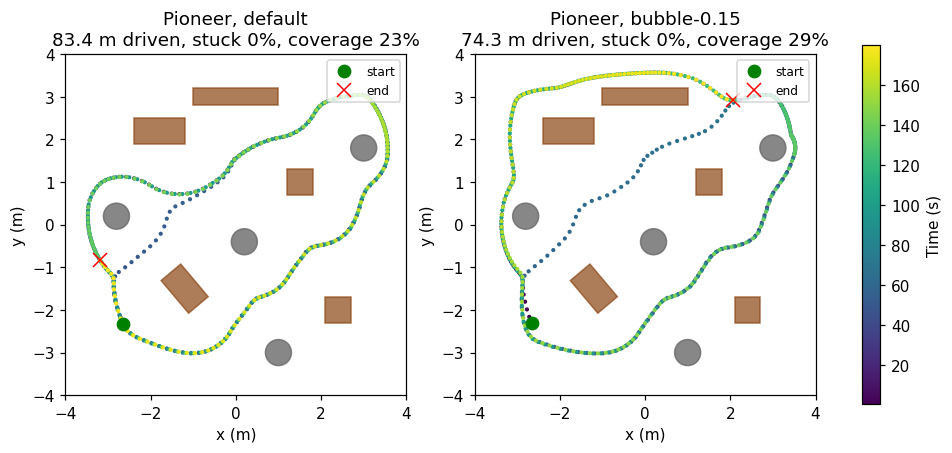

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5.3))
for ax, s in zip(axs, ["default", "bubble-0.15"]):
    if ("pioneer", s) not in runs:
        ax.set_visible(False); continue
    r = runs[("pioneer", s)][0]
    p = list(r["tracks"].values())[0]
    draw_obstacles(ax, obs_pioneer)
    sc = ax.scatter(p[:, 1], p[:, 2], c=p[:, 0], s=3, cmap="viridis", zorder=2)
    ax.plot(p[0, 1], p[0, 2], "go", ms=8, label="start", zorder=3)
    ax.plot(p[-1, 1], p[-1, 2], "rx", ms=9, label="end", zorder=3)
    per = r["per"][list(r["per"])[0]]
    ax.set(xlim=(-4, 4), ylim=(-4, 4), aspect="equal", xlabel="x (m)", ylabel="y (m)",
           title=f"Pioneer, {s}\n{per[0]:.1f} m driven, stuck {per[2]:.0f}%, coverage {r['cov']:.0f}%")
    ax.legend(fontsize=8, loc="upper right")
fig.colorbar(sc, ax=axs, label="Time (s)", shrink=0.8)
fig.savefig("figs/fig7_3_pioneer_trajectory.png", bbox_inches="tight")
plt.show()

## Exercise 1 (GUIDE.md §10) – speed vs safety: cruise sweep
Mean coverage and worst-robot stuck % against `cruise`, with ± 1 std over repeats.

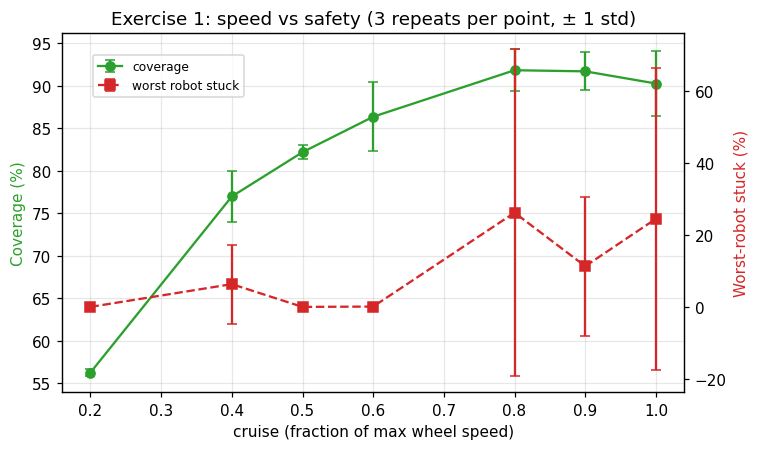

 cruise        coverage %     worst stuck %  repeats
    0.2      56.2 ±  0.4       0.0 ±  0.0        3
    0.4      77.0 ±  2.9       6.3 ± 11.0        3
    0.5      82.2 ±  0.8       0.0 ±  0.0        3
    0.6      86.3 ±  4.1       0.1 ±  0.2        3
    0.8      91.8 ±  2.4      26.2 ± 45.4        3
    0.9      91.7 ±  2.2      11.3 ± 19.4        3
    1.0      90.2 ±  3.8      24.5 ± 42.0        3


In [14]:
sweep = []
for s, lst in runs.items():
    if s[0] == "swarm" and (s[1] == "default" or s[1].startswith("cruise-")):
        c = 0.5 if s[1] == "default" else float(s[1].split("-")[1])
        cov = [r["cov"] for r in lst]
        worst = [max(v[2] for v in r["per"].values()) for r in lst]
        sweep.append((c, np.mean(cov), np.std(cov, ddof=1) if len(cov) > 1 else 0,
                      np.mean(worst), np.std(worst, ddof=1) if len(worst) > 1 else 0, len(lst)))
sweep = np.array(sorted(sweep))
if len(sweep):
    fig, ax1 = plt.subplots(figsize=(7, 4.2))
    ax1.errorbar(sweep[:, 0], sweep[:, 1], yerr=sweep[:, 2], fmt="o-", capsize=3, color="tab:green",
                 label="coverage")
    ax1.set_xlabel("cruise (fraction of max wheel speed)")
    ax1.set_ylabel("Coverage (%)", color="tab:green")
    ax2 = ax1.twinx()
    ax2.errorbar(sweep[:, 0], sweep[:, 3], yerr=sweep[:, 4], fmt="s--", capsize=3, color="tab:red",
                 label="worst robot stuck")
    ax2.set_ylabel("Worst-robot stuck (%)", color="tab:red")
    nrep = sorted({int(v) for v in sweep[:, 5]})
    ax1.set_title(f"Exercise 1: speed vs safety ({'/'.join(map(str, nrep))} repeats per point, ± 1 std)")
    ax1.grid(alpha=0.3)
    fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88), fontsize=8)
    fig.tight_layout()
    fig.savefig("figs/fig7_4_exercise1_cruise_sweep.png")
    plt.show()
    print(f"{'cruise':>7}{'coverage %':>18}{'worst stuck %':>18}{'repeats':>9}")
    for r in sweep:
        print(f"{r[0]:7.1f}{r[1]:10.1f} ± {r[2]:4.1f}{r[3]:10.1f} ± {r[4]:4.1f}{int(r[5]):9d}")
    np.savetxt("tables/T7_3a_exercise1_cruise_sweep.csv", sweep, fmt="%.2f", delimiter=",",
               header="cruise,coverage mean %,coverage std,worst stuck mean %,worst stuck std,repeats", comments="")

## Exercise 2 (GUIDE.md §10) – swapped wiring ("aggressive" vehicle)
Requires the edited controller (`wiring=-1`).

Setting              Repeats     Mean path (m)      Mean stuck %      Coverage %
default                    3       6.99 ± 0.00         0.0 ± 0.0      82.2 ± 0.8
wiring-aggressive          3       0.49 ± 0.05        93.0 ± 0.6      11.7 ± 1.6


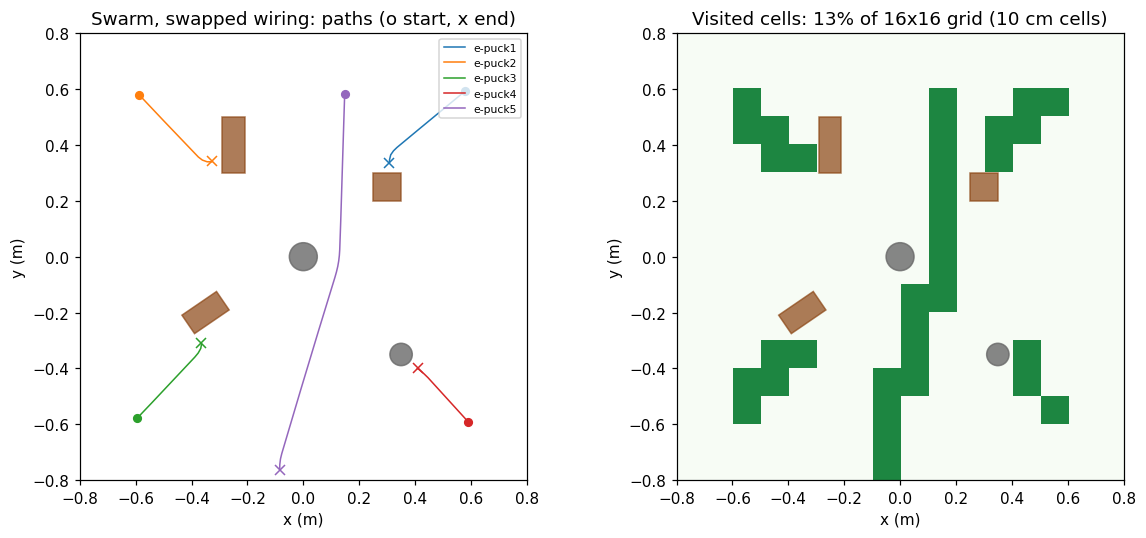

In [15]:
if ("swarm", "wiring-aggressive") in runs:
    ex2 = []
    for s in ["default", "wiring-aggressive"]:
        lst = runs[("swarm", s)]
        ex2.append([s, len(lst), ms([np.mean([v[0] for v in r["per"].values()]) for r in lst], "{:.2f}"),
                    ms([np.mean([v[2] for v in r["per"].values()]) for r in lst]),
                    ms([r["cov"] for r in lst])])
    print(f"{'Setting':<20}{'Repeats':>8}{'Mean path (m)':>18}{'Mean stuck %':>18}{'Coverage %':>16}")
    for r in ex2:
        print(f"{r[0]:<20}{r[1]:>8}{r[2]:>18}{r[3]:>18}{r[4]:>16}")
    np.savetxt("tables/T7_3b_exercise2_wiring.csv", np.array(ex2, dtype=object), fmt="%s", delimiter=";",
               header="Setting;Repeats;Mean path per robot (m);Mean stuck (%);Coverage (%)", comments="")
    plot_run(runs[("swarm", "wiring-aggressive")][0], "swarm", obs_swarm, "Swarm, swapped wiring",
             "figs/fig7_5_exercise2_aggressive_wiring.png")
else:
    print("No 'wiring-aggressive' runs found (Exercise 2 skipped).")